# Exercise 12: Deep and Convolutional Neural Network

### Premise: MNIST with Keras

> **MNIST dataset**: $6\cdot 10^4$ images of *handwritten digits* (0-9), comprised of a 28x28 pixel grid each taking values on a 256-valued grayscale gradation
>
> The whole dataset is avaiable as a part of the Keras package

We can load the data and convert them into a useful '*shape*':

In [1]:
import tensorflow as tf
from tensorflow import keras
import os
import numpy as np
import matplotlib.pyplot as plt
seed=0
np.random.seed(seed) # fix random seed
tf.random.set_seed(seed)

from keras.datasets import mnist

# input image dimensions
img_rows, img_cols = 28, 28 # number of pixels 
# output
num_classes = 10 # 10 digits

# the data, split between train and test sets
# X are the image matrices, Y are their correct labels
(X_train, Y_train), (X_test, Y_test) = mnist.load_data()

I0000 00:00:1794415640.690064   15890 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794415640.739772   15890 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794415641.889847   15890 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Secondly, consider a (*column*) array of $N$ labels, where its entries take $N_{c}$ different values (*classes*).

`keras.utils.to_categorical` returns a $N \times N_{c}$ matrix taking values in $\{0, 1\}$: each row contains a single $1$ at the index corresponding to the row's original label.

In [2]:
labels = np.array([0, 2, 1, 2, 0]) # considered a 5x1 column vector
print("Original column vector:")
print(labels)

print("Binary categorical matrix:")
print(keras.utils.to_categorical(labels))

Original column vector:
[0 2 1 2 0]
Binary categorical matrix:
[[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 0. 1.]
 [1. 0. 0.]]


Using this we can convert each image (*a $28\cdot 28 = 784$ column array taking values in $\{0, 1, ..., 255\}$) into a $784 \times 256$ binary matrix:

an example of a data point with label 4 before to_categorical


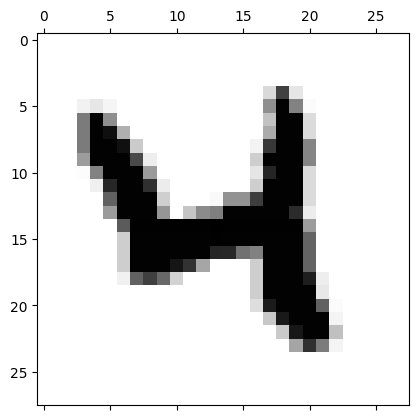

... and with label [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.] after to_categorical

X_train shape: (60000, 784)  = (N_samples, N_pixels)
Y_train shape: (60000, 10)  = (N_samples, N_labels)


In [3]:
# reshape data, cast to floats and rescale values within [0,1]
# each image is a single img_rows*img_cols row of pixels
X_train = X_train.reshape(X_train.shape[0], img_rows*img_cols)
X_train = X_train.astype('float32') / 255
X_test = X_test.reshape(X_test.shape[0], img_rows*img_cols)
X_test = X_test.astype('float32') / 255

# look at an example of data point
print('an example of a data point with label', Y_train[20], 'before to_categorical')
# matshow: display a matrix in a new figure window
# to print it it's temporarily reshaped into a 28x28 matrix
plt.matshow(X_train[20,:].reshape(28,28),cmap='binary')
plt.show()

# convert class values to binary class vectors, e.g. for use with categorical_crossentropy
Y_train = keras.utils.to_categorical(Y_train, num_classes)
Y_test = keras.utils.to_categorical(Y_test, num_classes)


print('... and with label', Y_train[20], 'after to_categorical')
print()
print('X_train shape:', X_train.shape, ' = (N_samples, N_pixels)')
print('Y_train shape:', Y_train.shape, ' = (N_samples, N_labels)')

- each $X$ datapoint is a $1 \times 784$ row vector containing each pixel value (*rescaled within $[0,1]$*)
- each $Y$ datapoint is a $1 \times 10$ binary array labeling the image

We can now create a deep neural network over these data structures, compile it choosing a loss function and additional metrics, then train it and evaluate its performance on test data:

In [4]:
from keras.models import Sequential
from keras.layers import Dense, Dropout
from keras.optimizers import SGD, Adam, RMSprop, Adagrad, Adadelta, Adam, Adamax, Nadam

def create_DNN():
    # instantiate model
    model = Sequential()
    # add a dense all-to-all relu layer
    model.add(Dense(400,input_shape=(img_rows*img_cols,), activation='relu'))
    # add a dense all-to-all relu layer
    model.add(Dense(100, activation='relu'))
    # apply dropout with rate 0.5
    model.add(Dropout(0.5))
    # soft-max layer
    model.add(Dense(num_classes, activation='softmax'))
    
    return model

def compile_model():
    # create the model
    model=create_DNN()
    print('Model architecture created successfully!')

    # compile the model
    model.compile(loss=keras.losses.categorical_crossentropy,
                  optimizer=SGD(),
                  metrics=['acc'])
    print('Model compiled successfully and ready to be trained.')
    return model

batch_size = 32
epochs = 5
model_DNN = compile_model()

# train DNN and store training info in history
history = model_DNN.fit(X_train, Y_train,
          batch_size=batch_size,
          epochs=epochs,
          shuffle=True, # a good idea is to shuffle input before at each epoch
          verbose=1,
          validation_data=(X_test, Y_test))

# evaluate model
score = model_DNN.evaluate(X_test, Y_test, verbose=1)
# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Model architecture created successfully!
Model compiled successfully and ready to be trained.
Epoch 1/5


/home/dario/coding/numerical_simulation_laboratory/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1794415643.015396   15890 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - acc: 0.7691 - loss: 0.7812 - val_acc: 0.9130 - val_loss: 0.3189
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - acc: 0.8877 - loss: 0.3864 - val_acc: 0.9293 - val_loss: 0.2422
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - acc: 0.9115 - loss: 0.3146 - val_acc: 0.9394 - val_loss: 0.2042
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - acc: 0.9246 - loss: 0.2669 - val_acc: 0.9483 - val_loss: 0.1760
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - acc: 0.9339 - loss: 0.2360 - val_acc: 0.9512 - val_loss: 0.1584
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - acc: 0.9512 - loss: 0.1584

Test loss: 0.15844835340976715
Test accuracy: 0.951200008392334


Now that the model has been trained, we can plot its performance on validation data during at each training epoch:

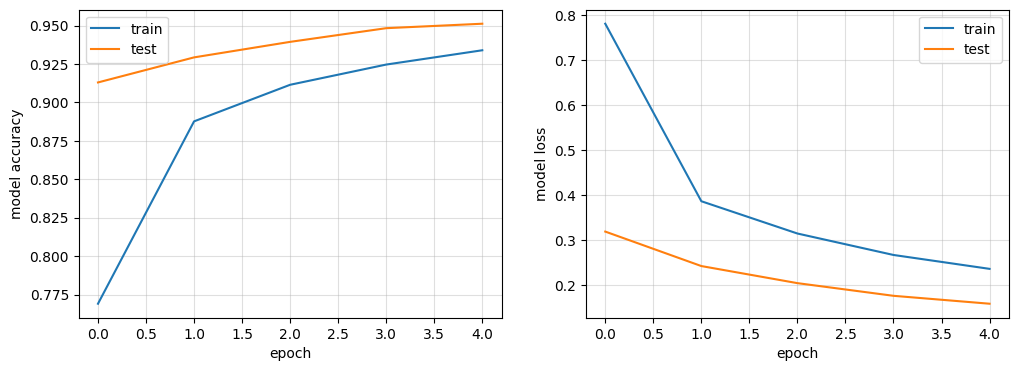

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# look into training history
# summarize history for accuracy
axs[0].plot(history.history['acc'])
axs[0].plot(history.history['val_acc'])
axs[0].set_ylabel('model accuracy')
# summarize history for loss
axs[1].plot(history.history['loss'])
axs[1].plot(history.history['val_loss'])
axs[1].set_ylabel('model loss')

for ax in axs:
    ax.set_xlabel('epoch')
    ax.grid(True, alpha=0.4)
    ax.legend(['train', 'test'], loc='best')

Note that dropout (*active only during training*) can turn off some '*weak classifier neurons*', improving efficiency but lowering accuracy. This leads to an improved *testing accuracy*, witout affecting *training accuracy*.

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


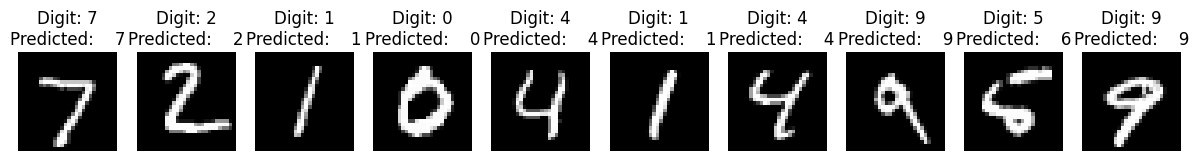

In [6]:
#X_test = X_test.reshape(X_test.shape[0], img_rows*img_cols)
predictions = model_DNN.predict(X_test)

X_test = X_test.reshape(X_test.shape[0], img_rows, img_cols,1)

plt.figure(figsize=(15, 15)) 
for i in range(10):    
    ax = plt.subplot(2, 10, i + 1)    
    plt.imshow(X_test[i, :, :, 0], cmap='gray')    
    plt.title("Digit: {}\nPredicted:    {}".format(np.argmax(Y_test[i]), np.argmax(predictions[i])))    
    plt.axis('off') 
plt.show()

### Ex.12.1: Create your own DNN
> ***goal**: create, with the same categorization goal, a DNN with different optimizers and increasing the number of training epochs and comment its performance in loss and accuracy*

To compare different optimizers' performance, we can loop through a dictionary:

In [7]:
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout
from keras.optimizers import SGD, Adam, RMSprop, Adagrad, Adadelta, Adamax, Nadam

def load_and_transform():
    # input/output shapes parameters
    img_rows, img_cols = 28, 28
    num_classes = 10

    # load data
    (X_train, Y_train), (X_test, Y_test) = mnist.load_data()

    # reshape data, cast to floats and rescale values within [0,1]
    # each image is a single img_rows*img_cols row of pixels
    X_train = X_train.reshape(X_train.shape[0], img_rows*img_cols)
    X_train = X_train.astype('float32') / 255
    X_test = X_test.reshape(X_test.shape[0], img_rows*img_cols)
    X_test = X_test.astype('float32') / 255

    # convert class values to binary class vectors, e.g. for use with categorical_crossentropy
    Y_train = keras.utils.to_categorical(Y_train, num_classes)
    Y_test = keras.utils.to_categorical(Y_test, num_classes)

    return {
        'X_train': X_train,
        'Y_train': Y_train,
        'X_test': X_test,
        'Y_test': Y_test
        }

def build_model(optimizer, img_size=28*28, num_classes=10):
    model = Sequential([
        Input(shape=(img_size,))
        ])
    model.add(Dense(400, activation='relu'))
    model.add(Dense(100, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(num_classes, activation='softmax'))

    model.compile(loss=keras.losses.categorical_crossentropy,
                  optimizer=optimizer,
                  metrics=['acc'])
    return model

def build_and_train(data, optimizer, batch_size=32, epochs=25, seed=0):
    keras.utils.set_random_seed(seed)
    model = build_model(optimizer)

    history = model.fit(data['X_train'], data['Y_train'],
          batch_size=batch_size,
          epochs=epochs,
          shuffle=True,
          verbose=1,
          validation_data=(data['X_test'], data['Y_test']))

    return model, history

print("Loading data...")
data = load_and_transform()
opts = {
    'Adam':     lambda: Adam(),
    'RMSprop':  lambda: RMSprop(),
    'Adagrad':  lambda: Adagrad(),
    'Adadelta': lambda: Adadelta(),
    'Adamax':   lambda: Adamax(),
    'Nadam':    lambda: Nadam(),
}
print("Data loaded.")

results = {}
for name, opt in opts.items():
    model, hist = build_and_train(data, opt())

    results[name] = hist.history
    loss, acc = model.evaluate(data['X_test'], data['Y_test'], verbose=0)
    print(f"{name:8s} test loss {loss:.4f}  test acc {acc:.4f}")

Loading data...
Data loaded.
Epoch 1/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - acc: 0.9192 - loss: 0.2783 - val_acc: 0.9684 - val_loss: 0.1046
Epoch 2/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - acc: 0.9638 - loss: 0.1227 - val_acc: 0.9712 - val_loss: 0.0933
Epoch 3/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - acc: 0.9748 - loss: 0.0862 - val_acc: 0.9722 - val_loss: 0.0952
Epoch 4/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - acc: 0.9791 - loss: 0.0697 - val_acc: 0.9749 - val_loss: 0.0847
Epoch 5/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - acc: 0.9840 - loss: 0.0532 - val_acc: 0.9807 - val_loss: 0.0810
Epoch 6/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - acc: 0.9869 - loss: 0.0438 - val_acc: 0.9774 - val_loss: 0.0926
Epoch 7/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - acc: 0.9877 - loss: 0.0410 - val_acc: 0.9807 - val_loss: 0.0940
Epoch 8/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - acc: 0.9893 - loss: 0.0348 - val_acc: 0.9793 - val_loss: 0.0928
Epoch 9/25


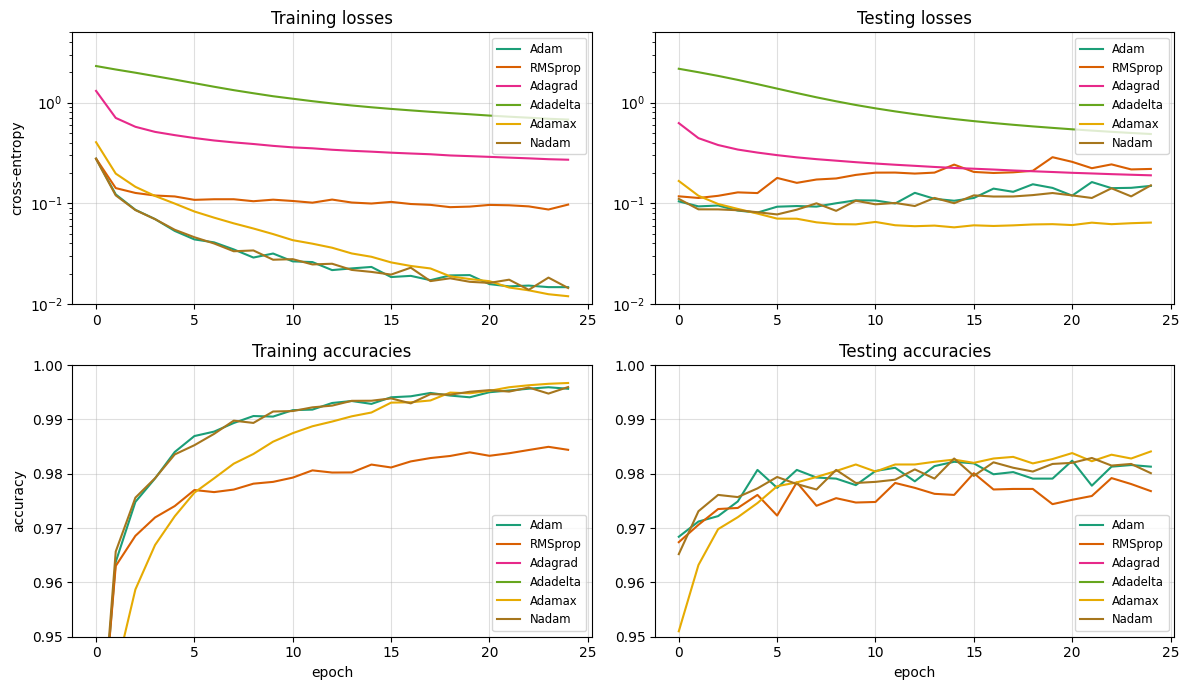

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
cmap = plt.get_cmap('Dark2')
colors = {name: cmap(x) for name, x in zip(results, np.linspace(0.1, 0.8, len(results)))}

for name, h in results.items():
    axes[0][0].plot(h['loss'], label=f'{name}', color=colors[name])
    axes[0][1].plot(h['val_loss'], label=f'{name}', color=colors[name])
    axes[1][0].plot(h['acc'], label=f'{name}', color=colors[name])
    axes[1][1].plot(h['val_acc'], label=f'{name}', color=colors[name])

axes[0][0].set_title('Training losses'); axes[0][1].set_title('Testing losses')
axes[1][0].set_title('Training accuracies'); axes[1][1].set_title('Testing accuracies')
axes[1][0].set_xlabel('epoch'); axes[1][1].set_xlabel('epoch')
axes[0][0].set_ylabel('cross-entropy'); axes[1][0].set_ylabel('accuracy')
axes[0][0].set_yscale("log"); axes[0][1].set_yscale("log")
axes[0][0].set_ylim(1e-2, 5); axes[0][1].set_ylim(1e-2, 5)
axes[1][0].set_ylim(0.95, 1.0); axes[1][1].set_ylim(0.95, 1.0)

for axs in axes:
    for ax in axs:
        ax.grid(True, alpha=0.4)
        ax.legend(loc="best", fontsize='small')
fig.tight_layout()

### Ex.12.2: Convolutional NN

To exploit the local relations between pixels and the translational invariance of digits recognition, we need to load data in a different shape: each image is now a $28x28x1$ collection of values in $[0,1]$ (single channel black and white image).

In [9]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras.datasets import mnist

def load_and_transform():
    # input/output shapes parameters
    img_rows, img_cols = 28, 28
    num_classes = 10

    # load data
    (X_train, Y_train), (X_test, Y_test) = mnist.load_data()

    X_train = X_train.astype('float32') / 255
    X_test = X_test.astype('float32') / 255
    X_train = X_train.reshape(X_train.shape[0], img_rows, img_cols, 1)
    X_test = X_test.reshape(X_test.shape[0], img_rows, img_cols, 1)
    input_shape = (img_rows, img_cols, 1)

    # convert class values to binary class vectors, e.g. for use with categorical_crossentropy
    Y_train = keras.utils.to_categorical(Y_train, num_classes)
    Y_test = keras.utils.to_categorical(Y_test, num_classes)

    return {
        'X_train': X_train,
        'Y_train': Y_train,
        'X_test': X_test,
        'Y_test': Y_test,
        'input_shape': input_shape
        }

data = load_and_transform()

Then we exploit the system's simmetries by building a Convolutional Neural Network:
- each `Conv2D()` layer is a combination of $10$ convolutions against $5 \times 5$ learnable filters: it encapsulates translational invariance and locality and is the defining feature of  CNN
- each `MaxPooling2D` reduces the number of parameters by pooling together $2 \times 2$ regions and taking their maximum
- each `Dropout(0.25)` (*active during training only*) sets the lower $25\%$ of its input to zero (rescaling all others accordingly): this lowers training accuracy, but makes the network more reliant on strong image features, improving its testing accuracy

then, after these layers,
- a `Flatten()` operation turns the $N \times N \times 1$ images back into $N^2$-values long arrays
- the large `Dense()` layer at the end is a fully-connected layer, nedded since digit recognition needs to categorize *global* features, not just local ones

lastly, the final `Dropout(0.5)` and `Dense(num_classes)` layers turn the results into class probabilities

In [10]:
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout, Flatten, Conv2D, MaxPooling2D
from keras.optimizers import SGD, Adam, RMSprop, Adagrad, Adadelta, Adamax, Nadam

def build_model(input_shape, num_classes=10):
    model = Sequential([
        Input(shape=input_shape),
        Conv2D(10, kernel_size=(5, 5), activation='relu'),  
        MaxPooling2D(pool_size=(2, 2)),
        Conv2D(20, kernel_size=(5, 5), activation='relu'),  
        MaxPooling2D(pool_size=(2, 2)), 
        Dropout(0.25),
        Flatten(),
        Dense(120, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax'),
    ])

    # compile the model
    model.compile(loss=keras.losses.categorical_crossentropy,
                  optimizer='Adamax',
                  metrics=['acc'])
    return model

def build_and_train(data, batch_size=32, epochs=25, seed=0):
    keras.utils.set_random_seed(seed)
    model = build_model(data['input_shape'])

    history = model.fit(data['X_train'], data['Y_train'],
      batch_size=batch_size,
      epochs=epochs,
      shuffle=True,
      verbose=1,
      validation_data=(data['X_test'], data['Y_test']))

    return model, history

model, hist = build_and_train(data)

Epoch 1/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - acc: 0.8476 - loss: 0.4828 - val_acc: 0.9652 - val_loss: 0.1148
Epoch 2/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - acc: 0.9417 - loss: 0.1939 - val_acc: 0.9753 - val_loss: 0.0773
Epoch 3/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - acc: 0.9568 - loss: 0.1478 - val_acc: 0.9808 - val_loss: 0.0599
Epoch 4/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - acc: 0.9631 - loss: 0.1244 - val_acc: 0.9840 - val_loss: 0.0516
Epoch 5/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - acc: 0.9672 - loss: 0.1090 - val_acc: 0.9861 - val_loss: 0.0448
Epoch 6/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - acc: 0.9714 - loss: 0.0968 - val_acc: 0.9872 - val_loss: 0.0401
Epoch 7/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - acc: 0.9730 - loss: 0.0914 - val_acc: 0.9883 - val_loss: 0.0362
Epoch 8/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - acc: 0.9759 - loss: 0.0821 - val_acc: 0.9886 - val_loss: 0.0353
Epoch 9/25
1875/1875 ━━━━━━━━━━━

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - acc: 0.9918 - loss: 0.0231

Test loss: 0.023124603554606438
Test accuracy: 0.9918000102043152


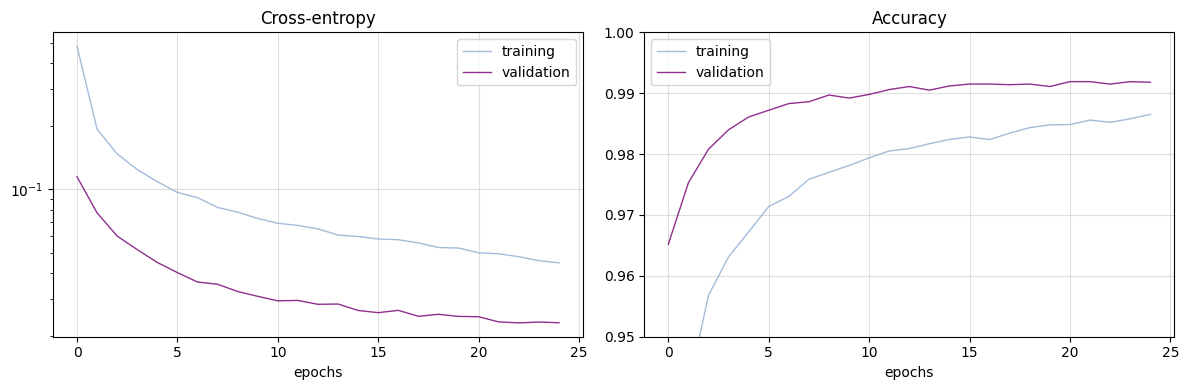

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = plt.cm.BuPu(np.linspace(0.4, 0.85, 2))

for ax, label, title in [
    (axes[0], 'loss', "Cross-entropy"),
    (axes[1], 'acc', "Accuracy"),
    ]:
    ax.plot(hist.history[label], alpha=0.9, lw=1.0, label='training', color=colors[0])
    ax.plot(hist.history['val_' + label], alpha=0.9, lw=1.0, label='validation', color=colors[1])
    ax.set_xlabel('epochs')
    ax.set_title(title)
axes[0].set_yscale("log"); axes[1].set_ylim(0.95, 1.0)

for ax in axes:
    ax.legend(loc="best")
    ax.grid(True, alpha=0.4)

fig.tight_layout()

score = model.evaluate(data['X_test'], data['Y_test'], verbose=1)
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])


We managed to reach a good *testing accuracy* of $99\%$ by combining local, translationally-invariant layers with global, totally-connected ones.

Note that the CNN's performance is better in testing than in training due to the presence of `Dropout` layers, active only during the latter.

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step


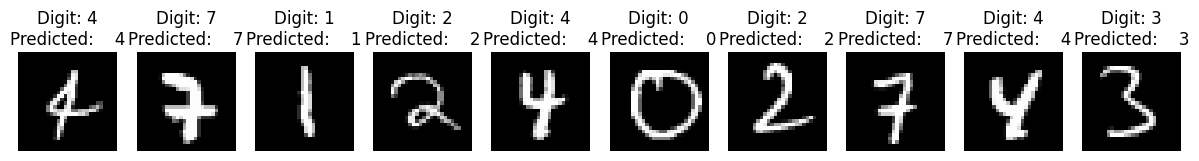

In [12]:
#X_test = X_test.reshape(X_test.shape[0], img_rows*img_cols)
predictions = model.predict(data['X_test'])

X_test = data['X_test'].reshape(data['X_test'].shape[0], 28, 28, 1)

lag = 300
plt.figure(figsize=(15, 15)) 
for i in range(lag, lag + 10):    
    ax = plt.subplot(2, 10, i - lag + 1)    
    plt.imshow(X_test[i, :, :, 0], cmap='gray')    
    plt.title("Digit: {}\nPredicted:    {}".format(np.argmax(data['Y_test'][i]), np.argmax(predictions[i])))    
    plt.axis('off') 
plt.show()

We can visually map the weights of any `Conv2D` filter as greyscale images too:

Layer index: 2
Filters in this layer: 20
Shape of these filters: 5x5x10


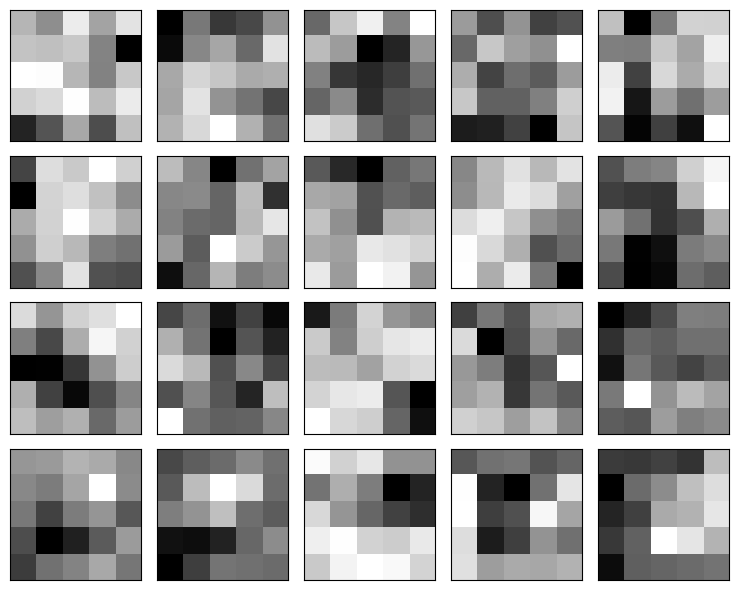

In [13]:
layer_index = 2   # can be 0 (first Conv2D layer) or 2 (second Conv2D layer)
filters, biases = model.layers[layer_index].get_weights()

# normalize filter values to 0-1 so we can visualize them
f_min, f_max = filters.min(), filters.max()
filters = (filters - f_min) / (f_max - f_min)
print(f"Layer index: {layer_index}"
      f"\nFilters in this layer: {filters.shape[-1]}"
      f"\nShape of these filters: {filters.shape[0]}x{filters.shape[1]}x{filters.shape[2]}")

# plot filters
n_filters = filters.shape[-1]
max_cols = 5
nrows = int(np.ceil(n_filters / max_cols))
ncols = min(max_cols, n_filters)

fig, axs = plt.subplots(nrows, ncols, figsize=(ncols*1.5, nrows*1.5))
for i in range(n_filters):
    row = i % max_cols
    col = i - row * max_cols
    f = filters[:, :, :, i]
    # specify subplot and turn of axis
    ax = plt.subplot(nrows, ncols, i + 1)
    ax.set_xticks([]); ax.set_yticks([])
    # plot filter channel in grayscale
    plt.imshow(f[:, :, 0], cmap='gray')
# show the figure
fig.tight_layout()

And lastly we can visualize the effect of these convolutional filters on one image of choice:

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 239ms/step


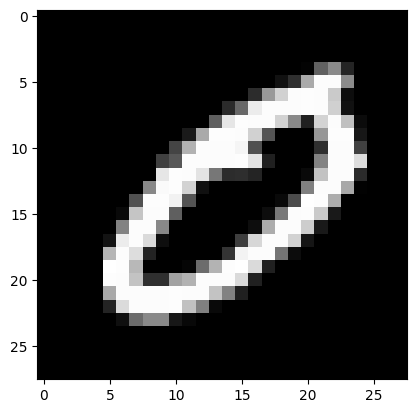

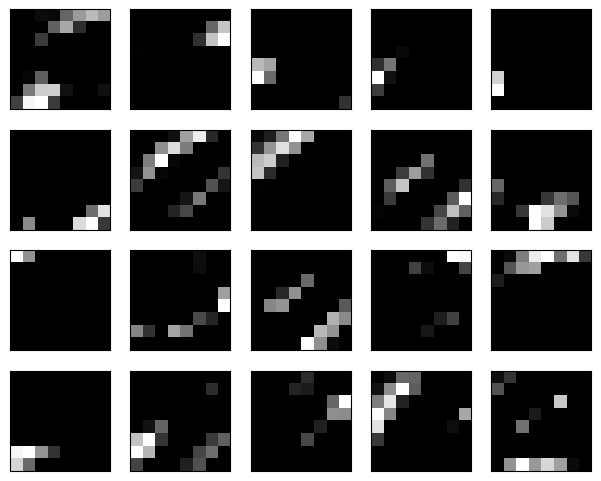

In [14]:
from keras.models import Model

image_index = 9753 # maximum 9999

layer_outputs = [layer.output for layer in model.layers]
activation_model = Model(inputs=model.inputs, outputs=layer_outputs)
activations = activation_model.predict(X_test[image_index].reshape(1,28,28,1))
 
def display_activation(activations, layer=0, nrows=2, ncols=4): 
    activation = activations[layer_index]
    activation_index=0
    fig, ax = plt.subplots(nrows, ncols, figsize=(ncols*1.5,nrows*1.5))
    for row in range(0,nrows):
        for col in range(0,ncols):
            ax[row][col].imshow(activation[0, :, :, activation_index], cmap='gray')
            ax[row][col].set_xticks([]); ax[row][col].set_yticks([])
            activation_index += 1

plt.imshow(X_test[image_index][:,:,0], cmap='gray')
display_activation(activations, layer=layer_index, nrows=nrows, ncols=ncols)

### Ex.12.3: Test with GIMP-written digits

> ***goal**: create your own $28 \times 28$ greyscale handwritten digits and test the CNN on their dataset*

After creating the files and saving them in './sim_results/handwritten_digits/' as '\<digit\>.png', we can load them as $(28 \times 28)$-shaped data using

Data shape:
(28, 28)


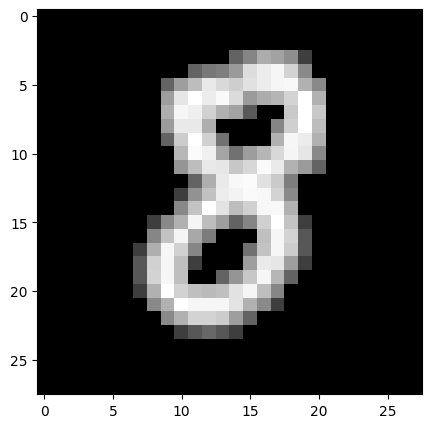

In [21]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import glob, os

dir_path = "./sim_results/handwritten_digits/"
def load_digit(path, nrows=28, ncols=28):
    img = Image.open(path).convert('L')
    xdim, ydim = img.size
    data = np.zeros((xdim, ydim))
    for j in range(ydim):
        for i in range(xdim):
            data[i,j] = img.load()[j,i]
    return data / 255

test_picture = load_digit(dir_path + "8.png")

print("Data shape:")
print(test_picture.shape)
plt.figure(figsize=(5,5))
plt.imshow(test_picture, cmap='gray')
plt.show()

Then load the whole directory with

In [22]:
files = sorted(glob.glob(dir_path + "*.png"))
labels = np.array([int(os.path.basename(f)[0]) for f in files])
X_mine = np.stack([load_digit(f) for f in files])

and feed them to the CNN:

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
CNN accuracy: 1.0


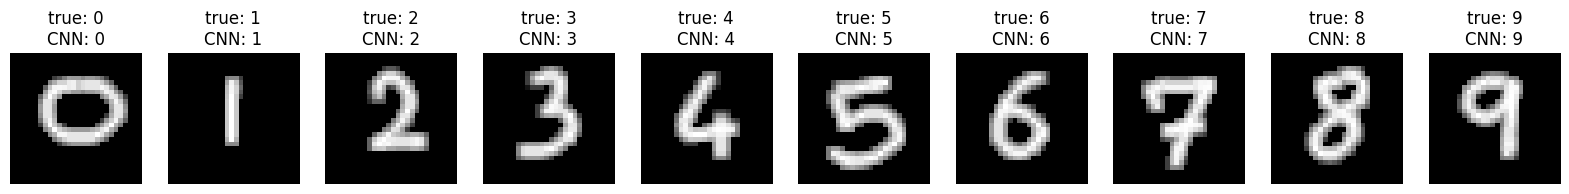

In [23]:
pred = model.predict(X_mine.reshape(-1, 28, 28, 1))
pred_labels = np.argmax(pred, axis=1)
print("CNN accuracy:", np.mean(pred_labels == labels))

n = len(files)
plt.figure(figsize=(2*n, 3))
for i in range(n):
    plt.subplot(1, n, i+1)
    plt.imshow(X_mine[i], cmap='gray')
    plt.title(f"true: {labels[i]}\nCNN: {pred_labels[i]}")
    plt.axis('off')
plt.show()